# Experiment 22: Independent Component Analysis and Component Visualization

An ECG recording contains overlapping sources. We create three independent periodic signals, mix them through a random matrix, then compare FastICA separation with PCA and measure source-to-recovery correlations.

**Tools:** Scikit-learn, NumPy, Matplotlib, SciPy.

**Embedded graph preview:** Static preview image included to match the reference notebooks. Run the code cell to produce plots from this experiment’s Python data.

## Tasks

1. Generate sine, square and sawtooth sources and mix them.  2. Recover sources with FastICA.  3. Apply PCA to the same mixture.  4. Plot original, mixed, ICA and PCA signals.  5. Compare recovery quality by correlation with the true sources.

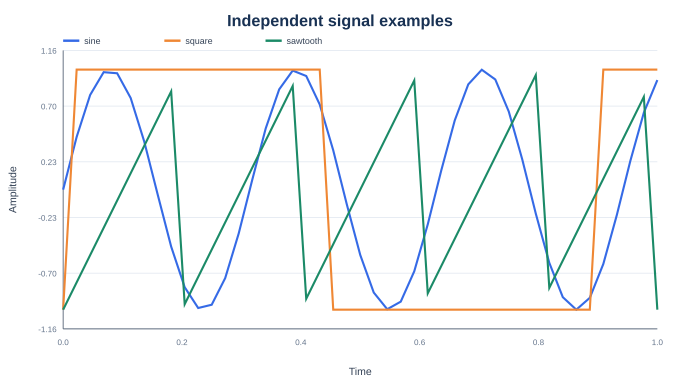

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import square, sawtooth
from sklearn.decomposition import FastICA, PCA
from scipy.optimize import linear_sum_assignment

rng=np.random.default_rng(22)
t=np.linspace(0,8,1200)
S=np.c_[np.sin(2*np.pi*.7*t),square(2*np.pi*.25*t),sawtooth(2*np.pi*.4*t)]
S=(S-S.mean(axis=0))/S.std(axis=0)
A=rng.uniform(.5,1.5,(3,3))
X=S@A.T
ica=FastICA(n_components=3,random_state=22,whiten="unit-variance",max_iter=1500)
S_ica=ica.fit_transform(X)
S_pca=PCA(n_components=3).fit_transform(X)
def best_correlations(reference,recovered):
    corr=np.corrcoef(reference.T,recovered.T)[:3,3:]
    rows,cols=linear_sum_assignment(-np.abs(corr))
    return corr[rows,cols]
print("Matched source/recovery correlations, FastICA:",np.round(best_correlations(S,S_ica),3))
print("Matched source/recovery correlations, PCA:    ",np.round(best_correlations(S,S_pca),3))
fig,axes=plt.subplots(4,1,figsize=(11,8),sharex=True)
series=[S,X,S_ica,S_pca]
titles=["Original independent sources","Observed mixtures","FastICA recovered components","PCA components"]
for ax,data,title in zip(axes,series,titles):
    offset=0
    for j in range(3):
        sig=data[:,j]
        ax.plot(t,sig+offset,label=f"component {j+1}")
        offset+=3.2
    ax.set_title(title,loc="left");ax.set_yticks([])
axes[-1].set_xlabel("Time");axes[0].legend(ncol=3,fontsize=8)
plt.tight_layout();plt.show()